# Spectral Methods

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/caam37830-sci-comp/notes/blob/main/05_differential_equations/spectral_methods.ipynb)

A finite difference formula approximates a derivative from a few neighboring values, and
its error is $O(h^p)$ for some fixed order $p$.  A **spectral method** instead fits one
global function through *all* the grid values, a trigonometric polynomial for periodic
problems, and differentiates that function exactly.  For smooth periodic functions the
error then decreases faster than any power of $h$.  The fast Fourier transform from
[Convolutions and Fourier Transforms](../02_linear_algebra/convolutions.ipynb) makes every
operation cost $O(N \log N)$.

This section covers Fourier spectral methods for periodic problems: differentiation, why
smoothness matters, linear PDEs solved exactly in Fourier space, Poisson's equation, and a
nonlinear wave equation.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sparse
import scipy.sparse.linalg as spla
from scipy.fft import fft, ifft, fft2, ifft2, fftfreq

## Fourier series on a grid

Take $N$ equally spaced points $x_j = jL/N$, $j = 0, \dots, N-1$, on a periodic interval
$[0, L)$.  Any vector of values $u_j$ can be written *exactly* as a combination of $N$
complex exponentials,

$$ u_j = \frac{1}{N} \sum_{k} \hat u_k\, e^{i k x_j}, $$

where $\hat u = $ `fft(u)` and the wavenumbers $k$ are integer multiples of $2\pi/L$.  The
FFT returns the coefficients in the order $0, 1, \dots, N/2 - 1, -N/2, \dots, -1$ (times
$2\pi/L$), and `fftfreq` produces the wavenumbers in the same order.

In [2]:
N = 8
print(fftfreq(N, d=1 / N))         # integer wavenumbers for a domain of length 2*pi

[ 0.  1.  2.  3. -4. -3. -2. -1.]


Since $\frac{d}{dx} e^{ikx} = ik\, e^{ikx}$, differentiating the interpolant takes three
steps: transform, multiply coefficient $k$ by $ik$, transform back.

One detail needs care.  For even $N$, the mode $k = -N/2$ takes the values $(-1)^j$ on the
grid, the sawtooth.  Both $e^{iNx/2}$ and $e^{-iNx/2}$ take those values, so the natural
real interpolant is $\cos(Nx/2)$, whose first derivative vanishes at every grid point.  For
odd derivatives we therefore set that coefficient to zero; otherwise a real function would
get a complex derivative.

In [3]:
def spectral_derivative(u, L=2 * np.pi, order=1):
    """
    derivative of the trigonometric interpolant of periodic samples u on [0, L)
    """
    N = len(u)
    k = 2 * np.pi * fftfreq(N, d=L / N)
    if order % 2 == 1 and N % 2 == 0:
        k[N // 2] = 0          # Nyquist mode: its odd derivatives vanish on the grid
    return np.real(ifft((1j * k)**order * fft(u)))


def fd2(u, h):
    """
    second-order centered difference for u', periodic
    """
    return (np.roll(u, -1) - np.roll(u, 1)) / (2 * h)


def fd4(u, h):
    """
    fourth-order centered difference for u', periodic
    """
    return (-np.roll(u, -2) + 8 * np.roll(u, -1) - 8 * np.roll(u, 1) + np.roll(u, 2)) / (12 * h)

Compare the three on $u(x) = e^{\sin x}$, whose derivative is $\cos x\, e^{\sin x}$.

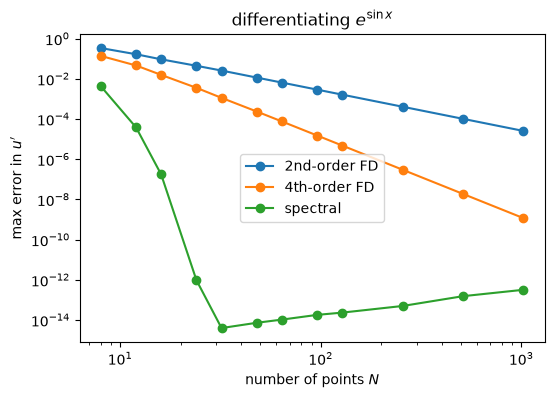

N =   8: spectral error 4.3e-03
N =  12: spectral error 3.8e-05
N =  16: spectral error 1.8e-07
N =  24: spectral error 9.5e-13
N =  32: spectral error 4.0e-15
N =  48: spectral error 7.3e-15


In [4]:
u = lambda x: np.exp(np.sin(x))
du = lambda x: np.cos(x) * np.exp(np.sin(x))

Ns = np.array([8, 12, 16, 24, 32, 48, 64, 96, 128, 256, 512, 1024])
errors = {"2nd-order FD": [], "4th-order FD": [], "spectral": []}
for N in Ns:
    x = 2 * np.pi * np.arange(N) / N
    h = 2 * np.pi / N
    errors["2nd-order FD"].append(np.max(np.abs(fd2(u(x), h) - du(x))))
    errors["4th-order FD"].append(np.max(np.abs(fd4(u(x), h) - du(x))))
    errors["spectral"].append(np.max(np.abs(spectral_derivative(u(x)) - du(x))))

plt.figure(figsize=(6, 4))
for name, e in errors.items():
    plt.loglog(Ns, e, 'o-', label=name)
plt.xlabel('number of points $N$')
plt.ylabel("max error in $u'$")
plt.legend()
plt.title(r'differentiating $e^{\sin x}$')
plt.show()

for N, e in zip(Ns, errors["spectral"]):
    if N <= 48:
        print(f"N = {N:3d}: spectral error {e:.1e}")

The finite difference errors fall like $N^{-2}$ and $N^{-4}$, straight lines on a log-log
plot.  The spectral error falls faster than any straight line, roughly a digit for every
couple of extra points, and reaches machine precision with about 32 points.  The
fourth-order formula needs about $10^3$ points to get to $10^{-9}$.  This behavior is
called **spectral accuracy**.

Past that point the spectral error creeps up slowly.  Differentiation multiplies the
rounding error in mode $k$ by $|k|$, which can be as large as $N/2$; this is the spectral
version of the round-off problem in [Differentiation](../04_functions/differentiation.ipynb).

## Smoothness sets the rate

The error of the spectral derivative is roughly the size of the Fourier coefficients that
the grid cannot represent, so it is governed by how fast the coefficients $\hat u_k$ decay.
That in turn is decided by smoothness.  A jump in $u$ gives coefficients of size about
$1/k$; a jump in the $p$-th derivative gives about $1/k^{p+1}$; and an analytic function
like $e^{\sin x}$ has coefficients that decay geometrically.

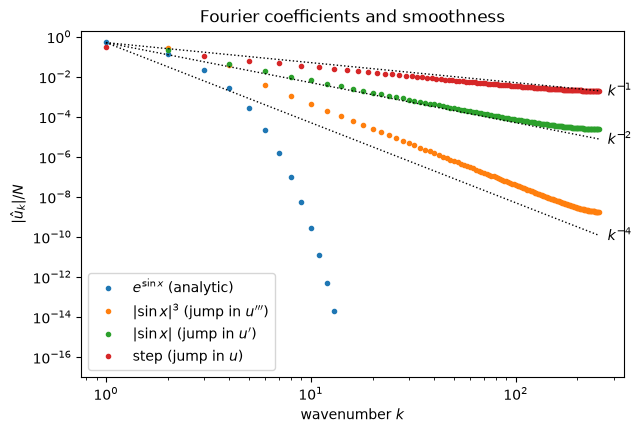

In [5]:
N = 512
x = 2 * np.pi * np.arange(N) / N
funcs = {
    r"$e^{\sin x}$ (analytic)": np.exp(np.sin(x)),
    r"$|\sin x|^3$ (jump in $u'''$)": np.abs(np.sin(x))**3,
    r"$|\sin x|$ (jump in $u'$)": np.abs(np.sin(x)),
    r"step (jump in $u$)": (x < np.pi).astype(float),
}
k = np.arange(1, N // 2)

plt.figure(figsize=(7, 4.5))
for name, v in funcs.items():
    c = np.abs(fft(v))[1:N // 2] / N
    keep = c > 1e-15        # coefficients that vanish by symmetry cannot go on a log plot
    plt.loglog(k[keep], c[keep], '.', label=name)
for p in [1, 2, 4]:
    plt.loglog(k, 0.5 / k**p, 'k:', lw=1)
    plt.text(k[-1] * 1.1, 0.5 / k[-1]**p, f'$k^{{-{p}}}$', va='center')
plt.ylim(1e-17, 2)
plt.xlabel('wavenumber $k$')
plt.ylabel(r'$|\hat u_k| / N$')
plt.legend(loc='lower left')
plt.title('Fourier coefficients and smoothness')
plt.show()

The derivative inherits these rates.  For $|\sin x|^3$ the spectral derivative converges
only algebraically:

In [6]:
v = lambda x: np.abs(np.sin(x))**3
dv = lambda x: 3 * np.sin(x) * np.abs(np.sin(x)) * np.cos(x)

for N in [16, 32, 64, 128, 256]:
    x = 2 * np.pi * np.arange(N) / N
    print(f"N = {N:3d}: max error {np.max(np.abs(spectral_derivative(v(x)) - dv(x))):.2e}")

N =  16: max error 1.71e-02
N =  32: max error 4.36e-03
N =  64: max error 1.09e-03
N = 128: max error 2.74e-04
N = 256: max error 6.85e-05


Each doubling of $N$ divides the error by 4, so it is $O(N^{-2})$, no better than a
second-order finite difference.  Spectral methods are spectacular for smooth periodic
problems and lose most of their advantage when the solution has kinks, jumps, or shocks.
A truncated Fourier series of a discontinuous function also overshoots near the jump by
about 9%, however many modes you keep (the Gibbs phenomenon).

## Linear PDEs: exact evolution in Fourier space

For a linear PDE with constant coefficients on a periodic domain, the Fourier modes evolve
independently.  For the heat equation $u_t = D u_{xx}$, the coefficient of $e^{ikx}$
satisfies $\hat u_k' = -Dk^2 \hat u_k$, so

$$ \hat u_k(t) = e^{-Dk^2 t}\, \hat u_k(0). $$

This solves the semi-discrete problem exactly in time, at any $t$, with one FFT and one
inverse FFT.  There is no time step and no stability limit.  The high wavenumbers decay
fastest; the sawtooth mode that made explicit Euler unstable in
[Time-Dependent PDEs](pde_time_evolution.ipynb) is here just a mode with decay rate
$D(N/2)^2$.

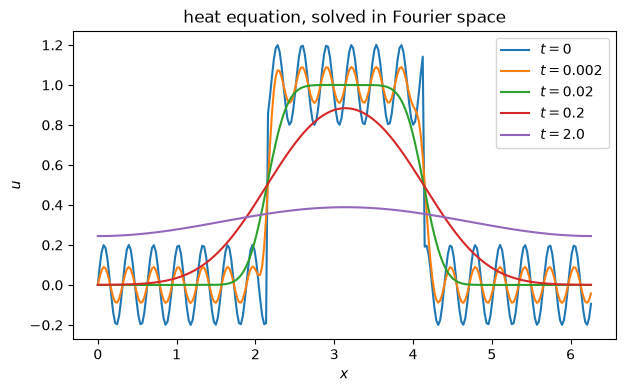

In [7]:
def heat_fourier(u0, t, D=1.0, L=2 * np.pi):
    """
    exact solution at time t of u_t = D u_xx on [0, L), periodic, from samples u0
    """
    N = len(u0)
    k = 2 * np.pi * fftfreq(N, d=L / N)
    return np.real(ifft(np.exp(-D * k**2 * t) * fft(u0)))


N = 256
x = 2 * np.pi * np.arange(N) / N
u0 = (np.abs(x - np.pi) < 1).astype(float) + 0.2 * np.sin(20 * x)

plt.figure(figsize=(7, 4))
for t in [0, 0.002, 0.02, 0.2, 2.0]:
    plt.plot(x, heat_fourier(u0, t), label=f'$t = {t}$')
plt.xlabel('$x$')
plt.ylabel('$u$')
plt.legend()
plt.title('heat equation, solved in Fourier space')
plt.show()

The $\sin 20x$ ripple decays like $e^{-400t}$ and is gone almost at once; the box smooths
out over times of order one; and the mean value, the $k = 0$ mode, never changes.

### Numerical diffusion and dispersion

The **advection equation** $u_t + c\,u_x = 0$ moves any profile to the right at speed $c$
without changing its shape.  In Fourier space $\hat u_k(t) = e^{-ickt}\hat u_k(0)$: every
mode just rotates in phase.  This makes it a sharp test of a spatial discretization.  We
move a narrow bump once around the domain, after which the exact solution is the initial
condition again, and compare

* first-order **upwind** differences, $u_x \approx (u_j - u_{j-1})/h$, with forward Euler;
* second-order **centered** differences with RK4 in time;
* **spectral** differentiation with RK4 in time;

all with the same time step $\Delta t = 0.5\,h/c$.

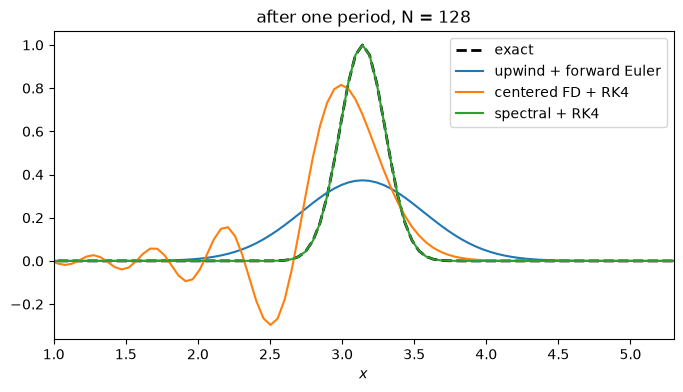

upwind      : max error 6.3e-01
centered FD : max error 4.5e-01
spectral    : max error 1.1e-03


In [8]:
def rk4_steps(rhs, u0, dt, nsteps):
    """
    nsteps of classical RK4 for the autonomous system u' = rhs(u)
    """
    u = u0.copy()
    for _ in range(nsteps):
        k1 = rhs(u)
        k2 = rhs(u + dt / 2 * k1)
        k3 = rhs(u + dt / 2 * k2)
        k4 = rhs(u + dt * k3)
        u = u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return u


N, c = 128, 1.0
h = 2 * np.pi / N
x = h * np.arange(N)
u0 = np.exp(-20 * (x - np.pi)**2)

T = 2 * np.pi / c                      # one trip around the domain
nsteps = int(round(T / (0.5 * h / c)))
dt = T / nsteps

u_up = u0.copy()
for _ in range(nsteps):
    u_up = u_up - c * dt / h * (u_up - np.roll(u_up, 1))

u_fd = rk4_steps(lambda u: -c * fd2(u, h), u0, dt, nsteps)
u_sp = rk4_steps(lambda u: -c * spectral_derivative(u), u0, dt, nsteps)

plt.figure(figsize=(8, 4))
plt.plot(x, u0, 'k--', lw=2, label='exact')
plt.plot(x, u_up, label='upwind + forward Euler')
plt.plot(x, u_fd, label='centered FD + RK4')
plt.plot(x, u_sp, label='spectral + RK4')
plt.xlim(1, 5.3)
plt.xlabel('$x$')
plt.legend()
plt.title(f'after one period, N = {N}')
plt.show()

for name, v in [("upwind", u_up), ("centered FD", u_fd), ("spectral", u_sp)]:
    print(f"{name:12}: max error {np.max(np.abs(v - u0)):.1e}")

The two finite difference schemes fail in different ways.

* **Upwind** smears the bump out.  Its truncation error behaves like an extra diffusion
  term $\tfrac{ch}{2}(1 - c\Delta t/h)\,u_{xx}$, called **numerical diffusion**.
* **Centered differences** keep the amplitude much better, but waves of different lengths
  travel at different speeds.  Applied to $e^{ikx}$, the centered difference gives
  $i\,\frac{\sin kh}{h}\, e^{ikx}$ instead of $ik\, e^{ikx}$, so mode $k$ moves at speed
  $c \frac{\sin kh}{kh} < c$.  The short waves lag behind and leave a trail of wiggles:
  **numerical dispersion**.
* The spectral derivative is exact for every mode the grid can represent, so the only
  error left is from RK4 in time.

The **modified wavenumber** $k_{\text{eff}}$, defined by "the scheme applied to $e^{ikx}$
gives $ik_{\text{eff}}\,e^{ikx}$", summarizes this.

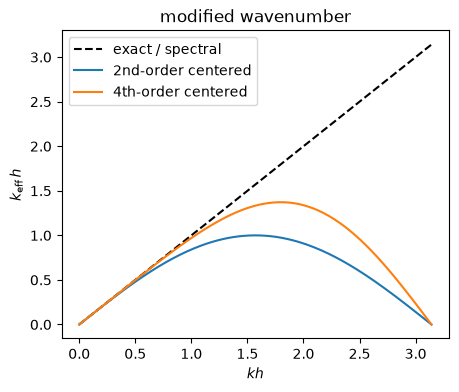

In [9]:
kh = np.linspace(0, np.pi, 200)
plt.figure(figsize=(5, 4))
plt.plot(kh, kh, 'k--', label='exact / spectral')
plt.plot(kh, np.sin(kh), label='2nd-order centered')
plt.plot(kh, (8 * np.sin(kh) - np.sin(2 * kh)) / 6, label='4th-order centered')
plt.xlabel('$kh$')
plt.ylabel(r'$k_{\mathrm{eff}}\, h$')
plt.legend()
plt.title('modified wavenumber')
plt.show()

Finite differences are accurate only for well-resolved modes, $kh \ll 1$, which means
many points per wavelength.  The spectral derivative is exact up to the grid's limit
$kh = \pi$, two points per wavelength.

## Poisson's equation

On the periodic square $[0, 2\pi)^2$ the Poisson equation $-\Delta u = f$ becomes, mode by
mode,

$$ (k_x^2 + k_y^2)\, \hat u_{k} = \hat f_{k}. $$

Every mode except $k = 0$ can be solved by division.  The $k = 0$ mode needs thought.
Integrating $-\Delta u = f$ over the domain gives $0 = \int f$, so a solution exists only
if $f$ has mean zero; and adding a constant to $u$ gives another solution, so we fix
$\hat u_0 = 0$ (zero mean).  The singularity of the problem shows up as exactly this one
zero denominator.

In [10]:
def poisson_periodic(f, L=2 * np.pi):
    """
    zero-mean solution of -Laplacian(u) = f on the periodic square [0, L)^2

    f must have (numerically) zero mean
    """
    N = f.shape[0]
    k = 2 * np.pi * fftfreq(N, d=L / N)
    kx, ky = np.meshgrid(k, k, indexing='ij')
    k2 = kx**2 + ky**2
    k2[0, 0] = 1.0                      # avoid dividing by zero; fixed below
    u_hat = fft2(f) / k2
    u_hat[0, 0] = 0.0                   # choose the solution with zero mean
    return np.real(ifft2(u_hat))

Check it with a manufactured solution: pick $u = e^{\sin x}\cos 2y$, compute
$f = -\Delta u$ by hand, and see if we get $u$ back.

In [11]:
for N in [64, 128, 256, 1024]:
    x = 2 * np.pi * np.arange(N) / N
    X, Y = np.meshgrid(x, x, indexing='ij')
    u_exact = np.exp(np.sin(X)) * np.cos(2 * Y)
    f = -(np.cos(X)**2 - np.sin(X) - 4) * u_exact         # -(u_xx + u_yy)
    start = time.perf_counter()
    u = poisson_periodic(f)
    elapsed = time.perf_counter() - start
    print(f"N = {N:4d} ({N * N:8d} unknowns): error {np.max(np.abs(u - u_exact)):.1e}, "
          f"{1e3 * elapsed:6.1f} ms")

N =   64 (    4096 unknowns): error 2.2e-15,    0.2 ms
N =  128 (   16384 unknowns): error 2.8e-15,    0.4 ms
N =  256 (   65536 unknowns): error 3.0e-15,    1.2 ms
N = 1024 ( 1048576 unknowns): error 3.1e-15,   31.2 ms


Machine precision on every grid, and a million unknowns in a few tens of milliseconds.
For comparison, here is a sparse direct solve of the second-order finite difference
version of the same problem ([Sparse Linear Algebra](../02_linear_algebra/sparse_linalg.ipynb)),
with one value pinned to remove the constant null space.

In [12]:
def periodic_laplacian_2d(N, L=2 * np.pi):
    """
    five-point finite difference Laplacian on an N x N periodic grid
    """
    h = L / N
    D = sparse.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(N, N), format='lil')
    D[0, -1] = D[-1, 0] = 1.0
    D = D.tocsr() / h**2
    I = sparse.identity(N, format='csr')
    return sparse.kron(D, I) + sparse.kron(I, D)


for N in [64, 128, 256]:
    A = (-periodic_laplacian_2d(N)).tolil()
    A[0, :] = 0
    A[0, 0] = 1.0                       # pin u at one point
    A = A.tocsc()
    b = np.random.default_rng(0).standard_normal(N * N)
    start = time.perf_counter()
    spla.spsolve(A, b)
    print(f"N = {N:4d}: sparse direct solve {time.perf_counter() - start:.3f} s")

N =   64: sparse direct solve 0.009 s


N =  128: sparse direct solve 0.077 s


N =  256: sparse direct solve 0.525 s


The sparse solve is already hundreds of times slower at $N = 256$, and it is only
second-order accurate.  Fast Poisson solvers based on the FFT, and on its relatives the
discrete sine and cosine transforms for Dirichlet and Neumann boundaries on rectangles,
are standard building blocks in fluid dynamics and electrostatics codes.

## Nonlinear problems: the pseudo-spectral method

Derivatives are easy in Fourier space, but products are easy in physical space.  A
**pseudo-spectral** method uses each where it is easy: compute derivatives with FFTs,
transform back to the grid, multiply pointwise, and repeat every time step.

Our example is the **Korteweg-de Vries (KdV) equation**

$$ u_t + u\,u_x + u_{xxx} = 0, $$

a model for shallow water waves.  It has **soliton** solutions, solitary waves that keep
their shape,

$$ u(x, t) = 3c\, \operatorname{sech}^2\!\left(\tfrac{\sqrt c}{2}\,(x - ct)\right), $$

which move at a speed $c$ proportional to their height.  Two difficulties appear.

**Stiffness.**  The term $u_{xxx}$ contributes $ik^3$ in Fourier space.  On 256 points
this reaches $2 \times 10^6$, so an explicit method would need time steps around $10^{-6}$
for stability alone (see [ODE Solvers](ode_solvers.ipynb)).  The cure is an **integrating
factor**: since the linear part is solved exactly by $\hat u_k(t) = e^{ik^3 t}\hat u_k(0)$,
change variables to $\hat v_k = e^{-ik^3 t}\hat u_k$.  The new variable satisfies

$$ \hat v_t = -\frac{ik}{2}\, e^{-ik^3 t}\, \mathcal F\!\left[\left(\mathcal F^{-1}\left[e^{ik^3t}\hat v\right]\right)^2\right], $$

using $u\,u_x = \tfrac12 (u^2)_x$.  The stiff term is gone, and we can use RK4.

**Aliasing.**  If $u$ contains wavenumbers up to $N/2$, then $u^2$ contains wavenumbers up
to $N$.  The grid cannot tell those apart from lower ones:

In [13]:
N = 16
x = 2 * np.pi * np.arange(N) / N
print("sin(14 x) on the grid: ", np.round(np.sin(14 * x), 3))
print("-sin(2 x) on the grid: ", np.round(-np.sin(2 * x), 3))

sin(14 x) on the grid:  [ 0.    -0.707 -1.    -0.707  0.     0.707  1.     0.707 -0.    -0.707
 -1.    -0.707 -0.     0.707  1.     0.707]
-sin(2 x) on the grid:  [-0.    -0.707 -1.    -0.707 -0.     0.707  1.     0.707  0.    -0.707
 -1.    -0.707 -0.     0.707  1.     0.707]


On 16 points, $\sin 14x$ and $-\sin 2x$ are the same vector, so energy that the
nonlinearity puts into wavenumber 14 shows up, wrongly, in wavenumber 2.  This is
**aliasing**.  The standard fix is the **2/3 rule**: zero out the top third of the
wavenumbers in the nonlinear term, so that products of the remaining modes cannot alias
back onto them.

Here is the solver.  It follows program 27 in Trefethen's *Spectral Methods in MATLAB*.

In [14]:
def kdv_solve(u0, dt, nsteps, dealias=False, save_every=None):
    """
    pseudo-spectral solution of u_t + u u_x + u_xxx = 0 on a periodic interval of length 2*pi

    the linear term is handled exactly by an integrating factor and the nonlinear
    term by RK4; returns the final state and a list of saved snapshots
    """
    N = len(u0)
    k = fftfreq(N, d=1 / N)
    k[N // 2] = 0                       # odd derivative: drop the Nyquist mode
    E = np.exp(0.5j * dt * k**3)        # integrating factor over half a step
    E2 = E**2
    g = -0.5j * dt * k                  # dt times the Fourier symbol of (u^2 / 2)_x
    if dealias:
        g = g * (np.abs(k) < N / 3)     # 2/3 rule
    nonlinear = lambda w: g * fft(np.real(ifft(w))**2)

    v = fft(u0)
    snapshots = [u0.copy()]
    for n in range(1, nsteps + 1):
        a = nonlinear(v)
        b = nonlinear(E * (v + a / 2))
        c = nonlinear(E * v + b / 2)
        d = nonlinear(E2 * v + E * c)
        v = E2 * v + (E2 * a + 2 * E * (b + c) + d) / 6
        if save_every and n % save_every == 0:
            snapshots.append(np.real(ifft(v)))
    return np.real(ifft(v)), snapshots


def soliton(x, c, x0=0.0):
    return 3 * c / np.cosh(0.5 * np.sqrt(c) * (x - x0))**2

Before using it, check it.  A soliton with speed $c = 100$ goes once around the domain of
length $2\pi$ in time $2\pi/100$ and should come back exactly to where it started.

In [15]:
N = 256
x = 2 * np.pi / N * np.arange(-N // 2, N // 2)          # grid on [-pi, pi)
u0 = soliton(x, c=100.0)

T = 2 * np.pi / 100
nsteps = int(np.ceil(T / (0.4 / N**2)))
uT, _ = kdv_solve(u0, T / nsteps, nsteps)
print(f"{nsteps} steps; relative error after one trip: "
      f"{np.max(np.abs(uT - u0)) / np.max(u0):.1e}")

10295 steps; relative error after one trip: 7.6e-08


Now the real experiment: a tall soliton starting behind a short one.  The tall one is
faster, catches up, and passes through.

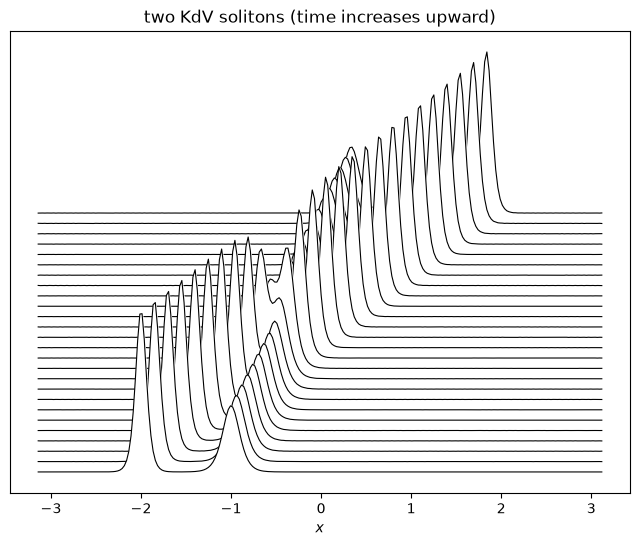

In [16]:
A, B = 25, 16                         # speeds A^2 = 625 and B^2 = 256
u0 = soliton(x, A**2, x0=-2) + soliton(x, B**2, x0=-1)
dt = 0.4 / N**2
tmax = 0.006
nsteps = int(round(tmax / dt))
save_every = nsteps // 25
uT, snaps = kdv_solve(u0, dt, nsteps, save_every=save_every)

fig, ax = plt.subplots(figsize=(8, 6))
for j, s in enumerate(snaps):
    offset = 120 * j
    front = 2 * (len(snaps) - j)        # earlier curves are in front and hide later ones
    ax.fill_between(x, offset, s + offset, color='white', zorder=front)
    ax.plot(x, s + offset, 'k', lw=0.8, zorder=front + 1)
ax.set_xlabel('$x$')
ax.set_yticks([])
ax.set_title('two KdV solitons (time increases upward)')
plt.show()

After the collision both solitons re-emerge with their original shapes and speeds.  The
only lasting effect of the interaction is a shift: the fast one ends up a little ahead of
where it would have been, the slow one a little behind.

**How accurate is this?**  KdV conserves the mass $\int u\,dx$ and the momentum
$\int u^2\,dx$.  The scheme conserves the mass exactly (the $k = 0$ mode never changes),
so the change in $\int u^2\,dx$ is the honest measure of the error.

In [17]:
print(f"{'N':>4} {'dt * N^2':>9} {'dealias':>8} {'steps':>6}   relative change in int u^2")
for N, factor, dealias in [(256, 0.4, False), (256, 0.2, False),
                           (512, 0.4, False), (512, 0.4, True)]:
    x = 2 * np.pi / N * np.arange(-N // 2, N // 2)
    u0 = soliton(x, A**2, x0=-2) + soliton(x, B**2, x0=-1)
    nsteps = int(round(tmax / (factor / N**2)))
    with np.errstate(over='ignore', invalid='ignore'):
        uT, _ = kdv_solve(u0, tmax / nsteps, nsteps, dealias=dealias)
    change = (np.sum(uT**2) - np.sum(u0**2)) / np.sum(u0**2)
    print(f"{N:4d} {factor:9.1f} {str(dealias):>8} {nsteps:6d}   {change:.1e}")

   N  dt * N^2  dealias  steps   relative change in int u^2
 256       0.4    False    983   -2.7e-03


 256       0.2    False   1966   -1.3e-04


 512       0.4    False   3932   nan


 512       0.4     True   3932   -4.9e-06


Three things to notice.

1. On 256 points, halving the time step reduces the drift by a factor of about 20, close
   to the $2^4 = 16$ expected from a fourth-order method, so on this grid the error is
   dominated by the time stepping.
2. On 512 points *without* dealiasing the computation blows up.  Aliasing feeds energy
   into the highest modes, where nothing removes it.  This is a genuine instability, not
   a lack of resolution: the finer grid made things worse.
3. With the 2/3 rule, the same 512-point run conserves $\int u^2$ to about $5 \times
   10^{-6}$.

## Beyond periodic problems

Fourier methods need periodicity.  Some pointers for other situations:

* **Non-periodic smooth problems** use Chebyshev polynomials instead of exponentials.
  The grid points cluster near the ends, like the Chebyshev nodes that tame the Runge
  phenomenon in [Interpolation](../04_functions/interpolation.ipynb), and spectral
  accuracy is recovered.  See `numpy.polynomial.chebyshev` and Trefethen's book.
* **Dirichlet or Neumann conditions on a rectangle**: the discrete sine and cosine
  transforms (`scipy.fft.dst`, `scipy.fft.dct`) diagonalize the standard second-difference
  matrix, giving $O(N \log N)$ Poisson solvers.
* **Shocks and discontinuities** cause Gibbs oscillations; finite volume methods are
  designed for them.
* **Complicated geometries** call for finite element methods (for example FEniCS).
  For spectral methods in production, look at [Dedalus](https://dedalus-project.org/).

## Exercises

### Exercise 1

Real data has conjugate-symmetric Fourier coefficients, so half of them are redundant.
Rewrite `spectral_derivative` using `rfft`, `irfft`, and `rfftfreq` from `scipy.fft`.
Check that it agrees with the version above to rounding error, and time both for
$N = 2^{20}$.

In [18]:
# Your code here

### Exercise 2

Compute the second derivative of $e^{\sin x}$ spectrally (`order=2`) and with the
second-order formula $(u_{j+1} - 2u_j + u_{j-1})/h^2$.  How many points does each need for
an error below $10^{-10}$?  (For the finite difference, extrapolate from the slope rather
than actually running it.)

In [19]:
# Your code here

### Exercise 3

Viscous **Burgers' equation** $u_t + u\,u_x = \nu u_{xx}$ on $[0, 2\pi)$ with
$u(x, 0) = \sin x$ steepens into a front whose width is about $\nu$.  Adapt `kdv_solve`:
the linear term is now $-\nu k^2$, so the integrating factor is $e^{-\nu k^2 t}$.  Solve up
to $t = 2$ for $\nu = 0.1$ and $\nu = 0.02$ on $N = 64$ and $N = 256$ points, with and
without the 2/3 rule.  When does the solution develop wiggles, and why?

In [20]:
# Your code here

### Exercise 4 (challenge)

The **Allen-Cahn equation** $u_t = \varepsilon^2 \Delta u + u - u^3$ models phase
separation.  On the periodic square $[0, 2\pi)^2$ use the semi-implicit scheme

$$ (1 + \Delta t\,\varepsilon^2 |k|^2)\, \hat u^{n+1}_k = \hat u^n_k + \Delta t\, \mathcal F\!\left[u^n - (u^n)^3\right]_k, $$

which treats the stiff Laplacian implicitly and the nonlinearity explicitly.  Start from
small random values with $\varepsilon = 0.05$, $N = 256$, $\Delta t = 0.1$, and show
snapshots of the domains forming and coarsening.  What happens to $\int u\,dx$ over time?

In [21]:
# Your code here